Estimating the value of a used car is one of the main everyday challenges in the automotive business. We believe that the sales price of a car is not only based on the value of the product itself, but is also heavily influenced by things like market trends, current availability, and politics.
With this challenge, we hope to raise some interest in this exciting topic and also gain some insight into what the main factors are that drive the value of a used car.

The data provided consists of almost 5000 real BMW cars that were sold via a b2b auction in 2018. The price shown in the table is the highest bid that was reached during the auction.

We have already done some data cleanup and filtered out cars with engine damage etc. However there may still be minor damages like scratches, but we do not have more information about that.

We have also extracted 8 criteria based on the equipment of cars that we think might have a good impact on the value of a used car. These criteria have been labeled feature1 to feature8 and are shown in the data below.

## 0. Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import LinearRegression, Lasso, Ridge, RidgeCV, LassoCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.metrics import root_mean_squared_error, r2_score
import bisect

import warnings
warnings.filterwarnings('ignore')

##  1. Reading data

In [2]:
import glob, os

# Look for the CSV next to the notebook, in a "data" folder, or one level up
# (works even if the file name has a prefix, e.g. "1791064286107_bmw_pricing_challenge.csv")
candidates = (glob.glob("data/*bmw_pricing_challenge*.csv")
              + glob.glob("*bmw_pricing_challenge*.csv")
              + glob.glob("../data/*bmw_pricing_challenge*.csv")
              + glob.glob("../*bmw_pricing_challenge*.csv"))
if not candidates:
    raise FileNotFoundError(
        "bmw_pricing_challenge.csv not found. Put the CSV in the same folder as this notebook "
        f"(current folder: {os.getcwd()})")

csv_path = candidates[0]
print("Reading:", csv_path)
df = pd.read_csv(csv_path)

Reading: bmw_pricing_challenge.csv


In [3]:
df.head()

,maker_key,model_key,mileage,engine_power,registration_date,fuel,paint_color,car_type,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,price,sold_at
0,BMW,118,140411,100,2012-02-01,diesel,black,convertible,True,True,False,False,True,True,True,False,11300,2018-01-01
1,BMW,M4,13929,317,2016-04-01,petrol,grey,convertible,True,True,False,False,False,True,True,True,69700,2018-02-01
2,BMW,320,183297,120,2012-04-01,diesel,white,convertible,False,False,False,False,True,False,True,False,10200,2018-02-01
3,BMW,420,128035,135,2014-07-01,diesel,red,convertible,True,True,False,False,True,True,True,True,25100,2018-02-01
4,BMW,425,97097,160,2014-12-01,diesel,silver,convertible,True,True,False,False,False,True,True,True,33400,2018-04-01


In [3]:
df.shape

(4843, 18)

In [4]:
df.describe()

,mileage,engine_power,price
count,4.843000e+03,4843.00000,4843.000000
mean,1.409628e+05,128.98823,15828.081767
std,6.019674e+04,38.99336,9220.285684
min,-6.400000e+01,0.00000,100.000000
25%,1.029135e+05,100.00000,10800.000000
50%,1.410800e+05,120.00000,14200.000000
75%,1.751955e+05,135.00000,18600.000000
max,1.000376e+06,423.00000,178500.000000


## 2. Exploratory Data Analysis

### 2.1. Missing Values

Check if the dataset contains any missing values.

In [5]:
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())
print("Duplicated rows:", df.duplicated().sum())

maker_key            0
model_key            0
mileage              0
engine_power         0
registration_date    0
fuel                 0
paint_color          0
car_type             0
feature_1            0
feature_2            0
feature_3            0
feature_4            0
feature_5            0
feature_6            0
feature_7            0
feature_8            0
price                0
sold_at              0
dtype: int64

Total missing values: 0
Duplicated rows: 0


There are no missing values. However, `df.describe()` showed some **impossible values**: a negative mileage, an engine power of 0 and a price of 100 €. We remove these few rows before going further.

In [6]:
print("mileage < 0      :", (df["mileage"] < 0).sum())
print("engine_power == 0:", (df["engine_power"] == 0).sum())
print("price < 1000     :", (df["price"] < 1000).sum())

df = df[(df["mileage"] >= 0) & (df["engine_power"] > 0) & (df["price"] >= 1000)].reset_index(drop=True)
print("Shape after cleaning:", df.shape)

mileage < 0      : 1
engine_power == 0: 1
price < 1000     : 62
Shape after cleaning: (4779, 18)


### 2.2. Distribution of the target variable

Plot the probabilistic distribution of the target variable.

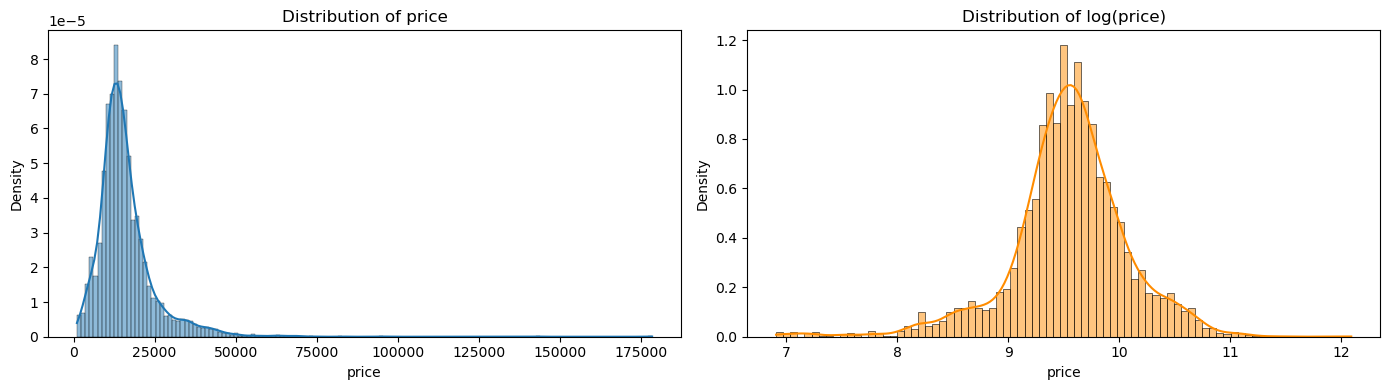

Skewness of price: 3.47


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df["price"], kde=True, stat="density", ax=axes[0])
axes[0].set_title("Distribution of price")
sns.histplot(np.log1p(df["price"]), kde=True, stat="density", ax=axes[1], color="darkorange")
axes[1].set_title("Distribution of log(price)")
plt.tight_layout()
plt.show()
print("Skewness of price:", round(df["price"].skew(), 2))

### 2.3. Distribution of numerical variables

Plot the probabilistic distribution of the numerical features.

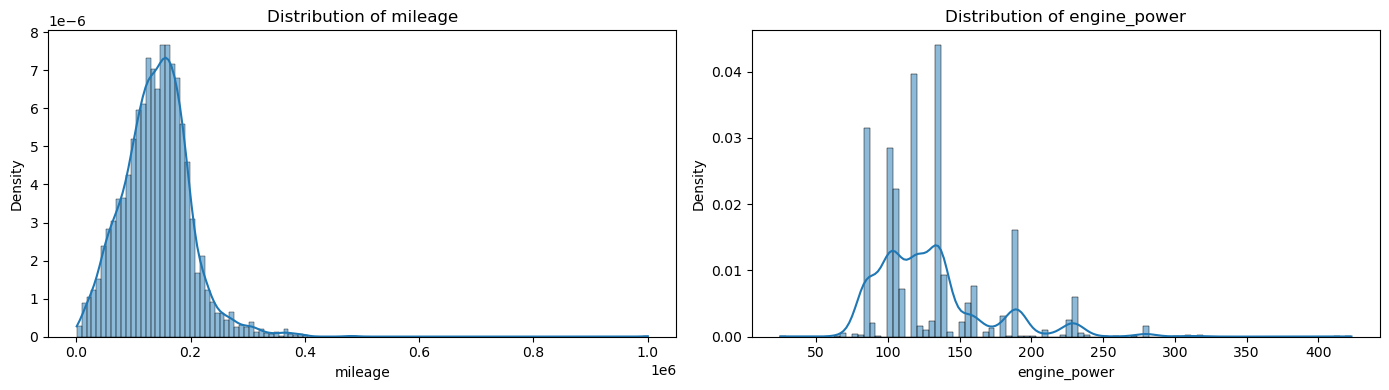

In [8]:
num_cols = ["mileage", "engine_power"]

fig, axes = plt.subplots(1, len(num_cols), figsize=(14, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], kde=True, stat="density", ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

### 2.4. Histogram of categorical variables

Plot the histogram of the categorical features.

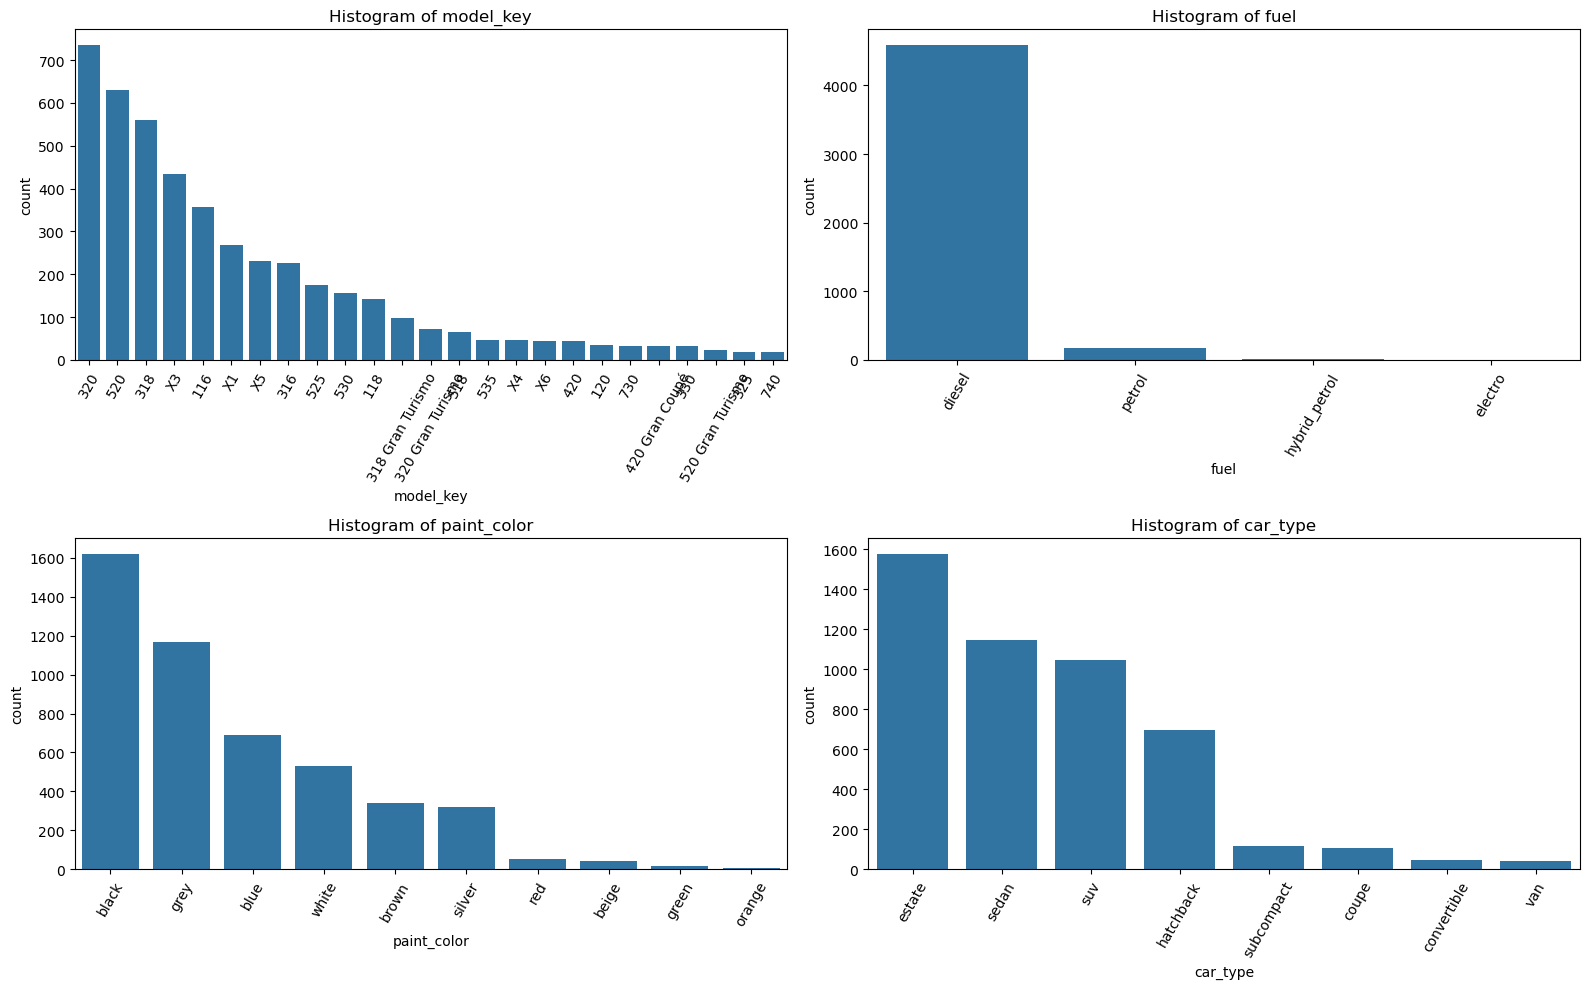

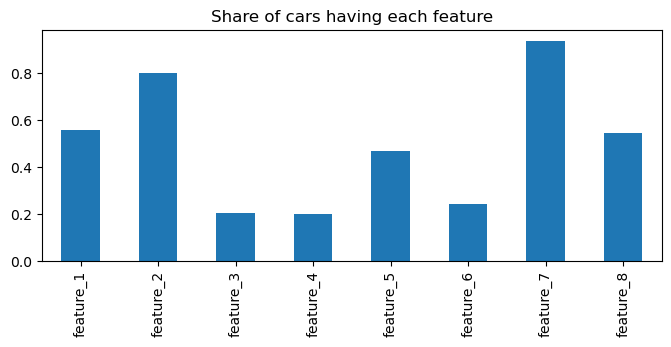

In [9]:
cat_cols = ["model_key", "fuel", "paint_color", "car_type"]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, col in zip(axes.ravel(), cat_cols):
    order = df[col].value_counts().index[:25]   # top 25 values for readability (model_key has many)
    sns.countplot(data=df, x=col, order=order, ax=ax)
    ax.set_title(f"Histogram of {col}")
    ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

bool_cols = [f"feature_{i}" for i in range(1, 9)]
df[bool_cols].mean().plot(kind="bar", figsize=(8, 3), title="Share of cars having each feature")
plt.show()

## 3. Data Splitting

Split the dataset into 2 training and test datasets.

In [10]:
X = df.drop(columns=["price"])
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (3823, 17) | Test: (956, 17)


We split **before** any fitted transformation (polynomial features, scaling, encoding) so that every transformer is fitted on the training set only: this avoids data leakage from the test set.

## 4. Feature Engineering

### 4.1. Removing non-predictive features

Remove any unnecessary feature.

In [11]:
print("Unique values of maker_key:", df["maker_key"].unique())

def remove_features(data):
    data = data.copy()
    reg = pd.to_datetime(data["registration_date"])
    sold = pd.to_datetime(data["sold_at"])
    # the two dates are not useful as such, but the age of the car at the sale is
    data["car_age"] = (sold - reg).dt.days / 365.25
    # maker_key has a single value (BMW) -> no information
    return data.drop(columns=["maker_key", "registration_date", "sold_at"])

X_train = remove_features(X_train)
X_test = remove_features(X_test)
X_train.head()

Unique values of maker_key: ['BMW']


,model_key,mileage,engine_power,fuel,paint_color,car_type,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,car_age
3308,320,153355,120,diesel,black,sedan,True,True,False,False,False,True,True,False,5.412731
3487,318,115485,100,diesel,blue,sedan,True,True,False,False,False,False,True,False,5.579740
3689,X3,130399,100,diesel,brown,suv,True,True,True,False,True,False,True,False,5.084189
4698,X3,13485,100,diesel,black,suv,True,True,False,False,False,False,True,False,2.165640
192,318,158853,100,diesel,black,estate,True,False,False,False,False,False,True,False,5.327858


- `maker_key` is constant (always BMW), so it carries no information.
- `registration_date` and `sold_at` are raw dates; we replace them by a more meaningful feature, `car_age` (age of the car in years at the time of the sale).

### 4.2. Creating new features

Creating polynomial features for numerical columns

In [12]:
num_cols = ["mileage", "engine_power", "car_age"]

poly = PolynomialFeatures(degree=2, include_bias=False)
poly_train = poly.fit_transform(X_train[num_cols])
poly_test = poly.transform(X_test[num_cols])
poly_names = poly.get_feature_names_out(num_cols)

poly_train = pd.DataFrame(poly_train, columns=poly_names, index=X_train.index)
poly_test = pd.DataFrame(poly_test, columns=poly_names, index=X_test.index)
print(list(poly_names))

['mileage', 'engine_power', 'car_age', 'mileage^2', 'mileage engine_power', 'mileage car_age', 'engine_power^2', 'engine_power car_age', 'car_age^2']


### 4.3. Scaling numerical variables

In [13]:
scaler = StandardScaler()
num_train = pd.DataFrame(scaler.fit_transform(poly_train), columns=poly_names, index=X_train.index)
num_test = pd.DataFrame(scaler.transform(poly_test), columns=poly_names, index=X_test.index)
num_train.describe().loc[["mean", "std"]].round(2)

,mileage,engine_power,car_age,mileage^2,mileage engine_power,mileage car_age,engine_power^2,engine_power car_age,car_age^2
mean,0.0,0.0,0.0,0.0,0.0,-0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


### 4.4. Categorical variables encoding

Convert categorical columns into numerical columns using label encoding or one-hot encoding.

In [14]:
cat_cols = ["model_key", "fuel", "paint_color", "car_type"]

# rare model_key values (< 10 cars) are grouped into an "infrequent" category,
# unknown categories in the test set are mapped to it
ohe = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False)
cat_train = pd.DataFrame(ohe.fit_transform(X_train[cat_cols]),
                         columns=ohe.get_feature_names_out(cat_cols), index=X_train.index)
cat_test = pd.DataFrame(ohe.transform(X_test[cat_cols]),
                        columns=ohe.get_feature_names_out(cat_cols), index=X_test.index)
print("Number of one-hot columns:", cat_train.shape[1])

Number of one-hot columns: 52


We use **one-hot encoding** rather than label encoding: these categories have no natural order, and label encoding would make a linear model believe that, for example, `model_key = 520` is "bigger" than `model_key = 320`.

### 4.5. Converting boolean columns

In [15]:
bool_cols = [f"feature_{i}" for i in range(1, 9)]
bool_train = X_train[bool_cols].astype(int)
bool_test = X_test[bool_cols].astype(int)

# final datasets
X_train_final = pd.concat([num_train, cat_train, bool_train], axis=1)
X_test_final = pd.concat([num_test, cat_test, bool_test], axis=1)
print("Final train shape:", X_train_final.shape)
print("Final test shape :", X_test_final.shape)

Final train shape: (3823, 69)
Final test shape : (956, 69)


## 5. Linear Regression

Fit a linear regression model on the training set. Evaluate the model on the testing set. Use the $R^2$ as an evaluation metric.

In [16]:
lr = LinearRegression()
lr.fit(X_train_final, y_train)
y_pred_lr = lr.predict(X_test_final)

r2_lr = r2_score(y_test, y_pred_lr)
print("Linear Regression - R2 test  :", round(r2_lr, 4))
print("Linear Regression - R2 train :", round(lr.score(X_train_final, y_train), 4))
print("Linear Regression - RMSE test:", round(root_mean_squared_error(y_test, y_pred_lr), 2))

Linear Regression - R2 test  : 0.8479
Linear Regression - R2 train : 0.7737
Linear Regression - RMSE test: 3368.33


Plot feature importance/weight.

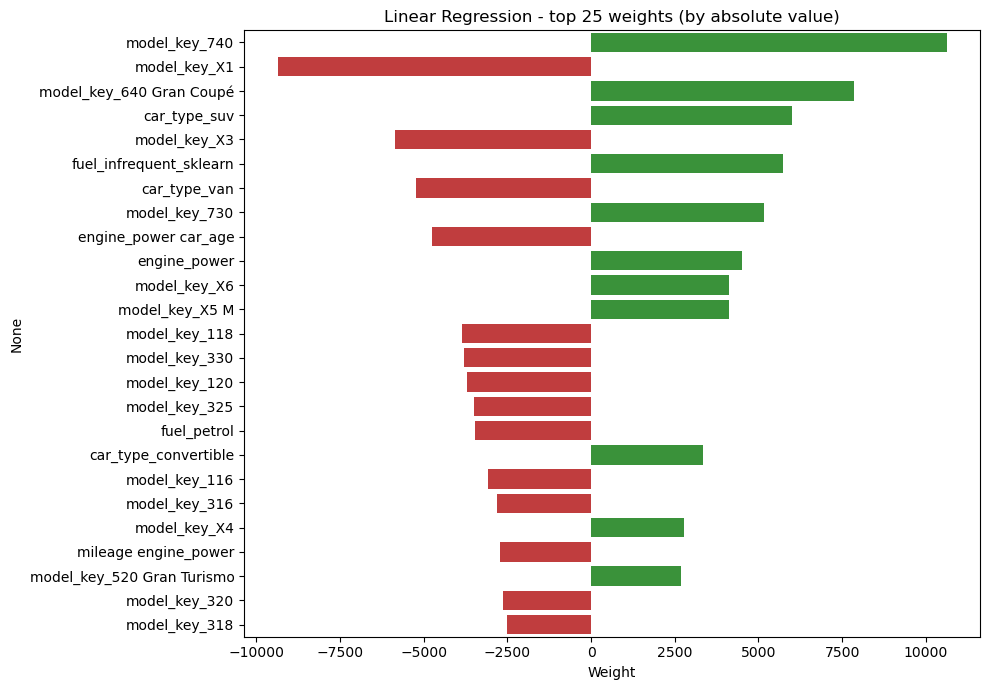

In [17]:
def plot_weights(model, columns, title, top=25):
    w = pd.Series(model.coef_, index=columns)
    w = w.reindex(w.abs().sort_values(ascending=False).index)[:top]
    plt.figure(figsize=(10, 7))
    sns.barplot(x=w.values, y=w.index, palette=["tab:green" if v > 0 else "tab:red" for v in w.values])
    plt.title(title)
    plt.xlabel("Weight")
    plt.tight_layout()
    plt.show()

plot_weights(lr, X_train_final.columns, "Linear Regression - top 25 weights (by absolute value)")

## 6. Ridge

Fit a ridge regression model on the training set. Use cross-validation in order to tune the regularization parameter of the ridge model. Evaluate the model on the testing set. Use the $R^2$ as an evaluation metric.

In [18]:
ridge = RidgeCV(alphas=np.logspace(-3, 3, 100), cv=5)
ridge.fit(X_train_final, y_train)
y_pred_ridge = ridge.predict(X_test_final)

r2_ridge = r2_score(y_test, y_pred_ridge)
print("Best alpha (Ridge):", round(ridge.alpha_, 4))
print("Ridge - R2 test  :", round(r2_ridge, 4))
print("Ridge - RMSE test:", round(root_mean_squared_error(y_test, y_pred_ridge), 2))

Best alpha (Ridge): 2.848
Ridge - R2 test  : 0.8477
Ridge - RMSE test: 3370.99


Plot feature importance/weight.

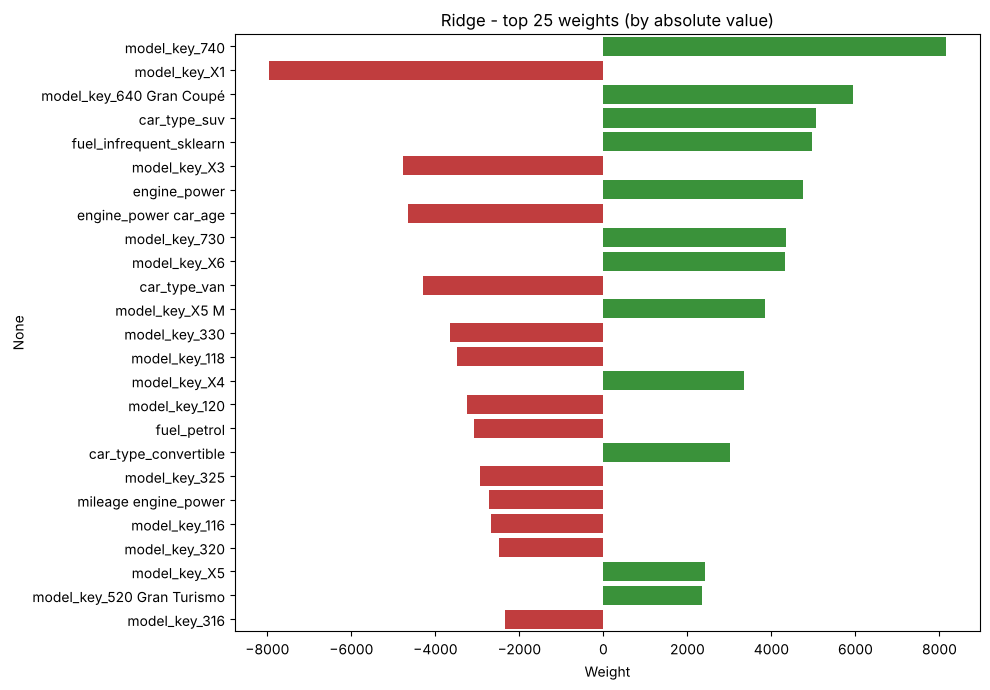

In [20]:
plot_weights(ridge, X_train_final.columns, "Ridge - top 25 weights (by absolute value)")

## 7. Lasso

Fit a lasso regression model on the training set. Use cross-validation in order to tune the regularization parameter of the lasso model. Evaluate the model on the testing set. Use the $R^2$ as an evaluation metric.

In [19]:
lasso = LassoCV(alphas=np.logspace(-2, 3, 100), cv=5, max_iter=100000, random_state=42)
lasso.fit(X_train_final, y_train)
y_pred_lasso = lasso.predict(X_test_final)

r2_lasso = r2_score(y_test, y_pred_lasso)
print("Best alpha (Lasso):", round(lasso.alpha_, 4))
print("Lasso - R2 test  :", round(r2_lasso, 4))
print("Lasso - RMSE test:", round(root_mean_squared_error(y_test, y_pred_lasso), 2))
print(f"Features set to 0 by Lasso: {(lasso.coef_ == 0).sum()} / {len(lasso.coef_)}")

Best alpha (Lasso): 2.3645
Lasso - R2 test  : 0.8487
Lasso - RMSE test: 3358.99
Features set to 0 by Lasso: 10 / 69


Plot feature importance/weight.

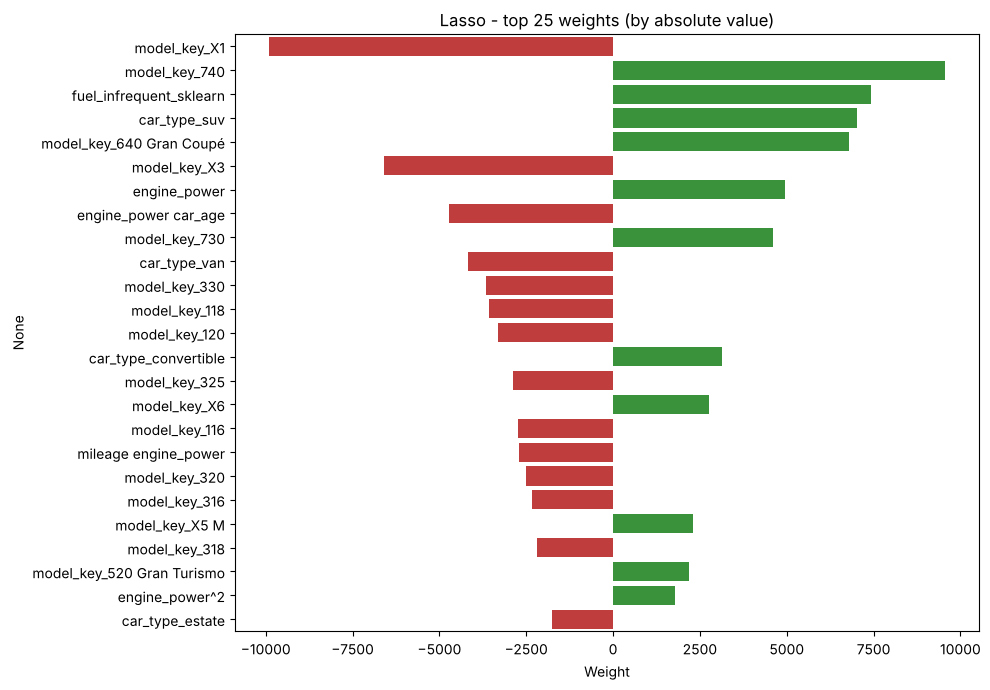

In [22]:
plot_weights(lasso, X_train_final.columns, "Lasso - top 25 weights (by absolute value)")

## 8. Comparison of the models

In [20]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge (CV)", "Lasso (CV)"],
    "R2 test": [r2_lr, r2_ridge, r2_lasso],
    "RMSE test": [root_mean_squared_error(y_test, p) for p in [y_pred_lr, y_pred_ridge, y_pred_lasso]],
}).round(4)
results

,Model,R2 test,RMSE test
0,Linear Regression,0.8479,3368.3349
1,Ridge (CV),0.8477,3370.9887
2,Lasso (CV),0.8487,3358.9886


**Conclusion:**
- The three linear models reach a similar $R^2$ on the test set; `engine_power`, `car_age` and `mileage` (and their polynomial terms) are among the strongest drivers of the price, together with some specific models (e.g. X-series, M-series).
- **Ridge** shrinks all the weights, which stabilises the model when many one-hot and polynomial features are correlated.
- **Lasso** sets part of the weights exactly to 0, so it also performs feature selection and gives a simpler, more interpretable model.
- The regularisation parameter $\alpha$ of Ridge and Lasso was chosen by 5-fold cross-validation on the training set only, so the test $R^2$ is an honest estimate.